# Projet d'évaluation : Fine-tuning d'un CNN pré-entraîné (ResNet50V2)
## Classification de fleurs en 5 classes (jeu de données `tf_flowers`)

---

### Contexte et objectif

Ce projet applique l'ensemble des notions vues en cours (apprentissage supervisé, fonctions d'activation, fonctions de coût, rétropropagation, optimisation, régularisation, réseaux convolutifs) à un cas concret : **réutiliser un CNN déjà entraîné sur ImageNet** et l'**adapter par fine-tuning** à une nouvelle tâche.

**Modèle choisi : `ResNet50V2`** (réseau résiduel de 50 couches, pré-entraîné sur ImageNet). Il ne fait pas partie de la famille VGG, comme demandé.

**Tâche :** classification multiclasse de photos de fleurs (daisy, dandelion, roses, sunflowers, tulips).

### Démarche

| Étape | Contenu |
|---|---|
| 1 | Configuration et hyperparamètres |
| 2 | Rappels théoriques illustrés par du code (activations, softmax, cross-entropy, descente de gradient, taille des convolutions) |
| 3 | Chargement, exploration et préparation des données (train / validation / test) |
| 4 | Data augmentation |
| 5 | Modèle de référence : petit CNN entraîné **from scratch** |
| 6 | Transfert d'apprentissage : phase 1 (extraction de caractéristiques, base gelée) |
| 7 | Fine-tuning : phase 2 (dégel partiel de la base, faible taux d'apprentissage), configuration raisonnée |
| 8 | **Optimisation des hyperparamètres** du fine-tuning : Grid Search, Random Search, wrapper scikit-learn avec validation croisée |
| 9 | Visualisation des filtres et des cartes de caractéristiques |
| 10 | Évaluation finale (métriques, matrice de confusion, analyse des erreurs) |
| 11 | Comparaison des approches, sauvegarde, inférence, conclusion |

### Correspondance avec les notions du cours

| Notion du cours | Où elle est appliquée |
|---|---|
| Classification multiclasse | Tout le projet (5 classes) |
| One-hot encoding | Étiquettes encodées avec `tf.one_hot` (section 3) |
| Sigmoid, Tanh, ReLU, Softmax | Rappels (section 2) ; ReLU dans les CNN, Softmax en sortie |
| Fonction de coût, cross-entropy, MSE, MAE | Rappels (section 2) ; `categorical_crossentropy` pour l'entraînement |
| Forward propagation, backpropagation, gradient | Rappels (section 2) et boucle `fit` |
| Gradient descent, mini-batch, batch, époque | Adam avec mini-batchs de 32 ; toy example en section 2 |
| Learning rate, learning rate adaptatif, convergence | Adam, `ReduceLROnPlateau`, deux learning rates (phase 1 et 2) |
| Régularisation L2 (weight decay), coefficient $\lambda$ | `kernel_regularizer=l2(...)` sur la couche de sortie |
| Dropout | Couche `Dropout` avant la sortie |
| Early stopping, patience, validation error | `EarlyStopping(monitor='val_loss', patience=...)` |
| Paramètres vs hyperparamètres | Poids appris par rétropropagation vs réglages choisis (section 8) |
| Grid Search | Recherche exhaustive sur une grille learning rate × nombre de couches dégelées (section 8.2) |
| Random Search | Tirage aléatoire (learning rate en échelle logarithmique, couches, dropout) (section 8.3) |
| Wrapper scikit-learn, `GridSearchCV`, `RandomizedSearchCV`, validation croisée | Réglage de la tête de classification avec SciKeras et cv=3 (section 8.4) |
| Jeu de validation vs jeu de test | Sélection des hyperparamètres sur la validation uniquement, test réservé à l'évaluation finale |
| CNN, convolution, filtre/noyau, feature map | Sections 5 et 8 |
| Stride, padding, pooling, max pooling, flatten | Modèle de référence (section 5), rappels (section 2) |
| Couche entièrement connectée | Tête de classification |
| Paramètres du réseau (poids et biais) | Comptage des paramètres entraînables / figés |
| Sur-apprentissage | Courbes train / validation, comparaison des modèles |

> Remarque : les notions spécifiques aux séquences (RNN, LSTM, GRU, BPTT) ne s'appliquent pas à ce projet d'images ; elles ont été traitées dans le lab précédent.

---
## 1. Configuration et hyperparamètres

In [1]:
import os
import pathlib
import tarfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPU disponible :", gpus if gpus else "aucun (activez un GPU : Exécution > Modifier le type d'exécution)")

TensorFlow : 2.21.0
Keras      : 3.13.2
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# ----- Reproductibilité -----
SEED = 42
keras.utils.set_random_seed(SEED)   # fixe les graines de Python, NumPy et TensorFlow

# ----- Hyperparamètres (regroupés au même endroit pour pouvoir les modifier facilement) -----
IMG_SIZE = (224, 224)     # taille attendue par ResNet50V2
BATCH_SIZE = 32           # taille du mini-batch
EPOCHS_HEAD = 10          # époques max, phase 1 (base gelée)
EPOCHS_FT = 15            # époques max, phase 2 (fine-tuning)
LR_HEAD = 1e-3            # learning rate de la phase 1 (on entraîne une couche neuve)
LR_FT = 1e-5              # learning rate de la phase 2 (très faible pour ne pas détruire les poids pré-entraînés)
L2_LAMBDA = 1e-4          # coefficient lambda de la régularisation L2
DROPOUT_RATE = 0.3        # proportion de neurones désactivés
FINE_TUNE_LAYERS = 30     # nombre de couches de la fin de la base que l'on dégèle
PATIENCE = 3              # patience de l'early stopping

sns.set_theme(style="whitegrid")

# ----- Optimisation des hyperparamètres (section 8) -----
RUN_SEARCH = True            # False pour sauter les recherches Grid / Random (gain de temps)
RUN_WRAPPER_SEARCH = True    # False pour sauter la recherche avec wrapper scikit-learn (SciKeras)
SEARCH_EPOCHS = 3            # époques maximum par essai (essais courts)
GRID_LRS = [1e-4, 1e-5, 1e-6]    # grille : learning rates du fine-tuning
GRID_LAYERS = [10, 30, 60]       # grille : nombre de couches dégelées
N_RANDOM_TRIALS = 6          # nombre d'essais du Random Search

**Justification des choix principaux**

| Hyperparamètre | Valeur | Raison |
|---|---|---|
| Optimiseur | Adam | Variante de la descente de gradient avec **taux d'apprentissage adaptatif** par paramètre et momentum : converge vite et nécessite peu de réglages |
| Batch size | 32 | Mini-batch gradient descent : compromis entre le bruit du SGD (1 exemple) et le coût du batch complet |
| LR phase 1 | $10^{-3}$ | La tête de classification est initialisée aléatoirement, elle peut apprendre vite |
| LR phase 2 | $10^{-5}$ | Les poids pré-entraînés sont déjà bons : de petits pas évitent l'**oubli catastrophique** |
| $\lambda$ (L2) | $10^{-4}$ | Pénalité légère, suffisante pour limiter l'amplitude des poids de la couche de sortie |
| Dropout | 0.3 | Régularisation modérée (la base pré-entraînée est déjà robuste) |
| Patience | 3 | Tolère de petites fluctuations de la `val_loss` avant d'arrêter |

---
## 2. Rappels théoriques illustrés

Cette section relie les notions du cours à de courts exemples exécutables.

### 2.1 Fonctions d'activation

$$\sigma(x)=\frac{1}{1+e^{-x}} \in ]0,1[ \qquad \tanh(x)\in ]-1,1[ \qquad \mathrm{ReLU}(x)=\max(0,x)$$

* **ReLU** est l'activation utilisée dans les couches cachées de ResNet : elle est simple, peu coûteuse et limite le problème de disparition du gradient.
* **Softmax** est utilisée en sortie pour obtenir une distribution de probabilités sur les classes.

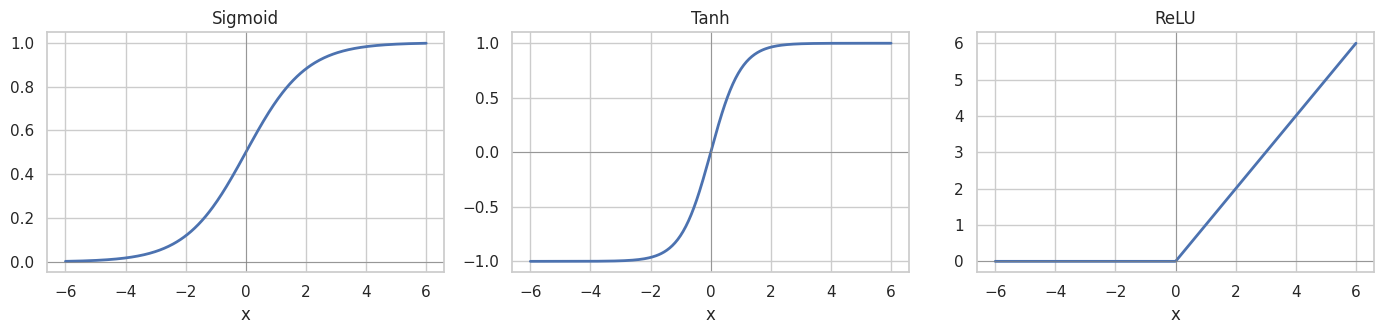

In [3]:
x = np.linspace(-6, 6, 400)
activations = {
    "Sigmoid": 1 / (1 + np.exp(-x)),
    "Tanh": np.tanh(x),
    "ReLU": np.maximum(0, x),
}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (name, y) in zip(axes, activations.items()):
    ax.plot(x, y, linewidth=2)
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.axvline(0, color='gray', linewidth=0.5)
    ax.set_title(name)
    ax.set_xlabel("x")
plt.tight_layout()
plt.show()

### 2.2 Softmax, one-hot encoding et fonctions de coût

Pour $K$ classes, avec les scores de sortie $z_k$ :

$$\mathrm{softmax}(z)_k=\frac{e^{z_k}}{\sum_j e^{z_j}}$$

* **One-hot** : la classe 0 sur 3 s'écrit $[1,0,0]$.
* **Cross-entropy** : $\;L=-\sum_k y_k\log(\hat y_k)\;$ (adaptée à la classification).
* **MSE** : $\frac1n\sum(y-\hat y)^2$ et **MAE** : $\frac1n\sum|y-\hat y|$ (plutôt utilisées en régression).

In [4]:
def softmax(z):
    e = np.exp(z - np.max(z))     # on soustrait le max pour la stabilité numérique
    return e / e.sum()

scores = np.array([2.0, 1.0, 0.1])      # sorties brutes du réseau (logits)
p = softmax(scores)                      # probabilités prédites
y_onehot = np.array([1, 0, 0])           # la vraie classe est la classe 0 (one-hot)

cross_entropy = -np.sum(y_onehot * np.log(p))
mse = np.mean((y_onehot - p) ** 2)
mae = np.mean(np.abs(y_onehot - p))

print("Probabilités softmax :", p.round(3), "| somme =", p.sum().round(3))
print(f"Cross-entropy : {cross_entropy:.4f}")
print(f"MSE           : {mse:.4f}")
print(f"MAE           : {mae:.4f}")

# Vérification avec Keras
ce_keras = keras.losses.CategoricalCrossentropy()(y_onehot[None, :], p[None, :]).numpy()
print(f"Cross-entropy (Keras) : {ce_keras:.4f}")

Probabilités softmax : [0.659 0.242 0.099] | somme = 1.0
Cross-entropy : 0.4170
MSE           : 0.0616
MAE           : 0.2273
Cross-entropy (Keras) : 0.4170


### 2.3 Descente de gradient et taux d'apprentissage

Mise à jour d'un paramètre $\theta$ avec le pas $\eta$ (learning rate) :

$$\theta \leftarrow \theta-\eta\,\frac{\partial J}{\partial \theta}$$

Sur la fonction simple $J(\theta)=\theta^2$ (gradient $2\theta$), on observe l'effet du learning rate :
* trop petit : convergence très lente ;
* adapté : convergence rapide ;
* trop grand : oscillations, voire **divergence**.

C'est exactement ce qui justifie le choix de deux learning rates différents et l'utilisation d'un learning rate adaptatif (Adam, `ReduceLROnPlateau`).

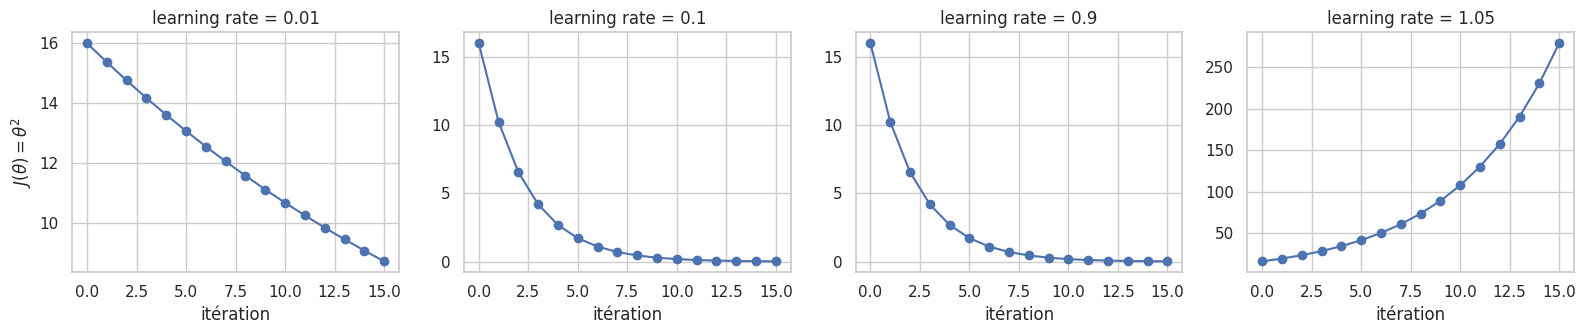

In [5]:
def gradient_descent_1d(lr, theta0=4.0, steps=15):
    """Descente de gradient sur J(theta) = theta^2."""
    theta = theta0
    trajectory = [theta]
    for _ in range(steps):
        grad = 2 * theta              # dJ/dtheta
        theta = theta - lr * grad     # mise à jour
        trajectory.append(theta)
    return np.array(trajectory)

learning_rates = [0.01, 0.1, 0.9, 1.05]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, lr in zip(axes, learning_rates):
    traj = gradient_descent_1d(lr)
    ax.plot(traj ** 2, marker='o')
    ax.set_title(f"learning rate = {lr}")
    ax.set_xlabel("itération")
axes[0].set_ylabel(r"$J(\theta)=\theta^2$")
plt.tight_layout()
plt.show()

### 2.4 Taille de sortie d'une convolution ou d'un pooling

$$n_{out}=\left\lfloor\frac{n_{in}+2p-f}{s}\right\rfloor+1$$

avec $f$ la taille du filtre, $s$ le stride et $p$ le padding.

In [6]:
def conv_output_size(n, f, s, p):
    return (n + 2 * p - f) // s + 1

print("Conv 7x7, stride 2, padding 3 sur 224 (1ère couche de ResNet) :", conv_output_size(224, 7, 2, 3))
print("MaxPooling 3x3, stride 2, padding 1 sur 112                  :", conv_output_size(112, 3, 2, 1))
print("MaxPooling 2x2, stride 2 sur 28 (modèle de référence)        :", conv_output_size(28, 2, 2, 0))

Conv 7x7, stride 2, padding 3 sur 224 (1ère couche de ResNet) : 112
MaxPooling 3x3, stride 2, padding 1 sur 112                  : 56
MaxPooling 2x2, stride 2 sur 28 (modèle de référence)        : 14


---
## 3. Chargement et préparation des données

Le jeu `tf_flowers` contient **3 670 images** de fleurs, réparties en 5 classes. Il est découpé en trois parties :

* **70 % entraînement** : ajustement des poids ;
* **15 % validation** : réglage, early stopping, learning rate adaptatif ;
* **15 % test** : évaluation finale, **jamais utilisée pour prendre des décisions**.

In [7]:
# Téléchargement de l'archive officielle des photos de fleurs (3 670 images JPEG, 5 dossiers = 5 classes)
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
# Téléchargement de l'archive (sans extraction automatique)
archive = tf.keras.utils.get_file("flower_photos.tgz", origin=DATA_URL)

# Extraction explicite dans un dossier connu (ne se refait pas si le dossier existe déjà)
extract_dir = pathlib.Path("flower_data")
if not extract_dir.exists():
    with tarfile.open(archive) as tar:
        try:
            tar.extractall(extract_dir, filter="data")      # Python >= 3.12
        except TypeError:
            tar.extractall(extract_dir)                     # anciennes versions de Python

# Le dossier des images est celui qui contient le sous-dossier "daisy"
data_dir = next(extract_dir.rglob("daisy")).parent
print("Dossier des images :", data_dir)

# Classes = noms des sous-dossiers (ordre alphabétique)
class_names = sorted(p.name for p in data_dir.iterdir() if p.is_dir())
num_classes = len(class_names)
print("Classes :", class_names)
print("Nombre de classes :", num_classes)

# Liste de tous les fichiers avec leur étiquette entière
all_paths, all_labels = [], []
for label, name in enumerate(class_names):
    for f in sorted((data_dir / name).glob("*.jpg")):
        all_paths.append(str(f))
        all_labels.append(label)
all_paths = np.array(all_paths)
all_labels = np.array(all_labels)

# Découpage aléatoire mais reproductible : 70 % train / 15 % validation / 15 % test
perm = np.random.default_rng(SEED).permutation(len(all_paths))
n_train = int(0.70 * len(perm))
n_val = int(0.15 * len(perm))
idx_train, idx_val, idx_test = perm[:n_train], perm[n_train:n_train + n_val], perm[n_train + n_val:]

def load_image(path, label):
    image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)    # image de taille variable
    return image, label

def make_raw_dataset(idx):
    ds = tf.data.Dataset.from_tensor_slices((all_paths[idx], all_labels[idx]))
    return ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

ds_train_raw = make_raw_dataset(idx_train)
ds_val_raw = make_raw_dataset(idx_val)
ds_test_raw = make_raw_dataset(idx_test)
print(f"Total : {len(all_paths)} images")

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Dossier des images : flower_data/flower_photos
Classes : ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Nombre de classes : 5
Total : 3670 images


Train : 2569 images | Validation : 550 | Test : 551


,Train,Validation,Test
daisy,445,104,84
dandelion,633,126,139
roses,455,96,90
sunflowers,480,104,115
tulips,556,120,123


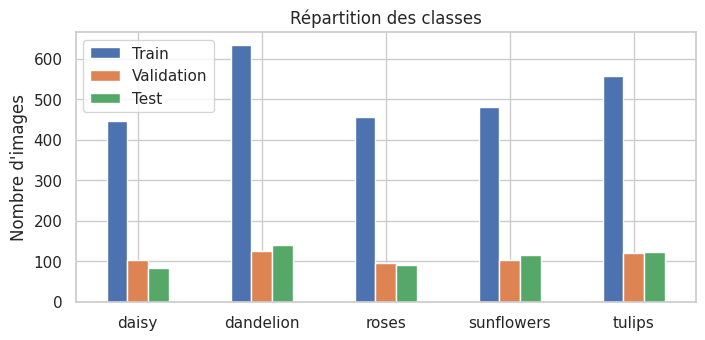

In [8]:
def get_labels(ds):
    return np.array([int(label) for _, label in ds.as_numpy_iterator()])

labels_train = get_labels(ds_train_raw)
labels_val = get_labels(ds_val_raw)
labels_test = get_labels(ds_test_raw)

print(f"Train : {len(labels_train)} images | Validation : {len(labels_val)} | Test : {len(labels_test)}")

# Répartition des classes dans chaque partie (vérifie l'équilibre)
dist = pd.DataFrame({
    "Train": np.bincount(labels_train, minlength=num_classes),
    "Validation": np.bincount(labels_val, minlength=num_classes),
    "Test": np.bincount(labels_test, minlength=num_classes),
}, index=class_names)
display(dist)

dist.plot(kind='bar', figsize=(8, 3.5), title="Répartition des classes")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=0)
plt.show()

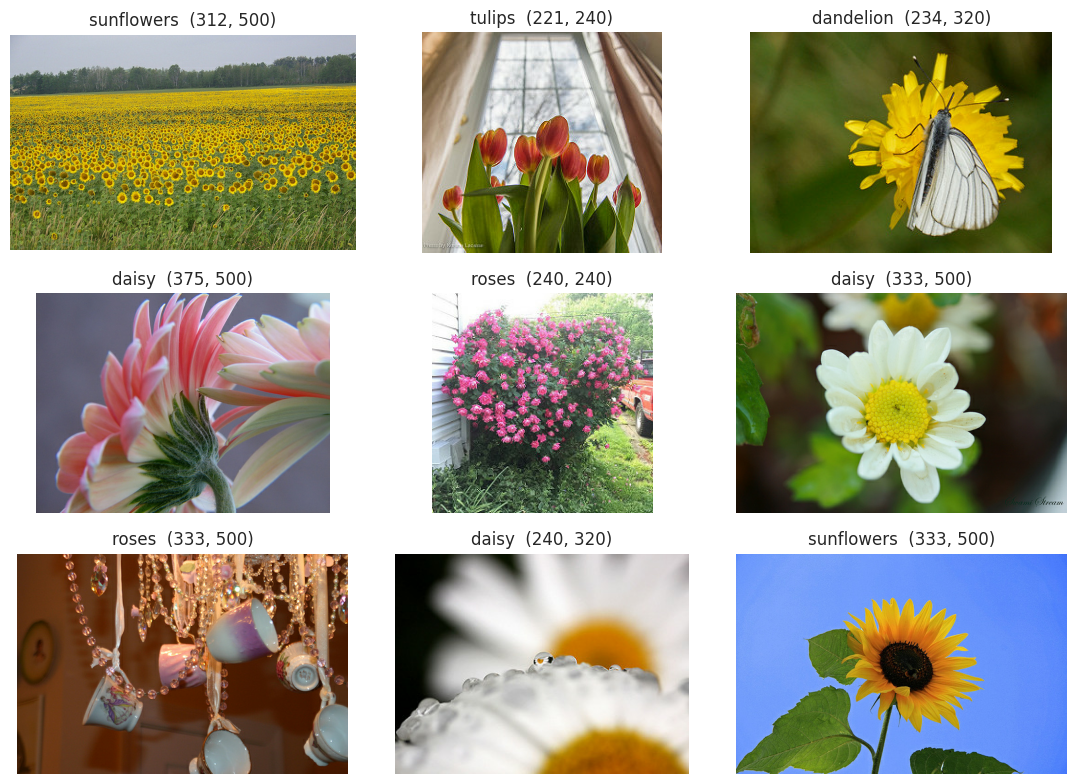

In [9]:
# Aperçu de quelques images (de tailles variables à ce stade)
plt.figure(figsize=(11, 8))
for i, (image, label) in enumerate(ds_train_raw.take(9)):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image.numpy())
    plt.title(f"{class_names[int(label)]}  {image.shape[:2]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

### Pipeline de données

Pour chaque image :
1. **Redimensionnement** en 224×224 (taille attendue par ResNet50V2) ;
2. **One-hot encoding** de l'étiquette ;
3. mise en **cache** en mémoire (les images sont stockées en `uint8` pour économiser la RAM) ;
4. **mélange** (uniquement pour l'entraînement : chaque époque voit les données dans un ordre différent) ;
5. découpage en **mini-batchs** et préchargement (`prefetch`) pour que le GPU ne soit jamais en attente.

La normalisation des pixels est faite **à l'intérieur du modèle** (couche `Rescaling`), ce qui garantit que la même transformation est appliquée à l'entraînement et à l'inférence.

In [10]:
def preprocess(image, label):
    image = tf.image.resize(image, IMG_SIZE)                          # redimensionnement
    image = tf.cast(tf.clip_by_value(image, 0, 255), tf.uint8)        # stockage compact
    label = tf.one_hot(label, num_classes)                            # one-hot encoding
    return image, label

def to_float(image, label):
    return tf.cast(image, tf.float32), label

def prepare(ds, training=False):
    ds = ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE).cache()
    ds = ds.map(to_float, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(1000, seed=SEED)       # mélange uniquement pour l'entraînement
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = prepare(ds_train_raw, training=True)
val_ds = prepare(ds_val_raw)
test_ds = prepare(ds_test_raw)

images, labels = next(iter(train_ds))
print("Forme d'un batch d'images    :", images.shape)
print("Forme d'un batch d'étiquettes:", labels.shape, "(one-hot)")
print("Exemple d'étiquette one-hot  :", labels[0].numpy())

Forme d'un batch d'images    : (32, 224, 224, 3)
Forme d'un batch d'étiquettes: (32, 5) (one-hot)
Exemple d'étiquette one-hot  : [1. 0. 0. 0. 0.]


---
## 4. Data augmentation

La data augmentation applique des transformations aléatoires aux images **pendant l'entraînement uniquement** (retournement, rotation, zoom, contraste). Le modèle voit ainsi des variantes différentes d'une même image à chaque époque, ce qui joue le rôle d'une **régularisation** : il devient plus difficile de mémoriser les exemples, donc le sur-apprentissage diminue.

Ces couches sont automatiquement désactivées lors de l'évaluation et de la prédiction.

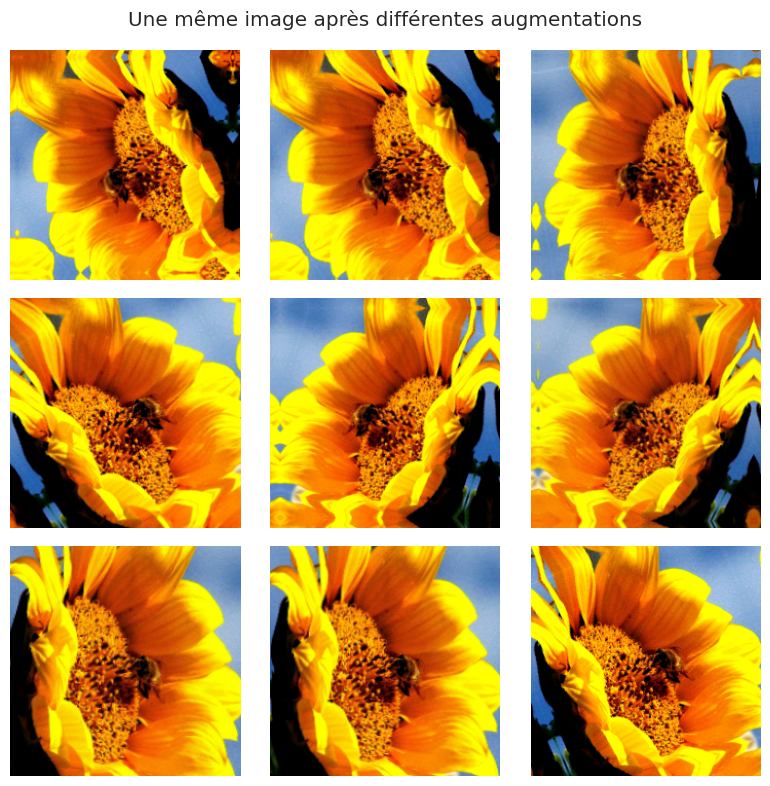

In [11]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

# Visualisation : 9 versions augmentées de la même image
sample_images, _ = next(iter(train_ds))
img = sample_images[0]

plt.figure(figsize=(8, 8))
for i in range(9):
    augmented = data_augmentation(tf.expand_dims(img, 0), training=True)
    plt.subplot(3, 3, i + 1)
    plt.imshow(augmented[0].numpy().astype("uint8"))
    plt.axis('off')
plt.suptitle("Une même image après différentes augmentations")
plt.tight_layout()
plt.show()

---
## 5. Modèle de référence : CNN entraîné from scratch

Avant d'utiliser le transfert d'apprentissage, on entraîne un **petit CNN depuis zéro**. Il sert de point de comparaison pour mesurer l'apport du modèle pré-entraîné.

Architecture classique, avec les notions du cours :

* **Conv2D** : filtres $3\times3$, `padding='same'`, activation ReLU, pour détecter des motifs locaux (la profondeur augmente : 32, 64, 128 filtres) ;
* **MaxPooling2D** : filtre $2\times2$, **stride 2**, pour réduire la taille spatiale des cartes de caractéristiques ;
* **Flatten** : transforme les cartes de caractéristiques en vecteur ;
* **Dense** (couche entièrement connectée) avec régularisation L2 et **Dropout** ;
* **Softmax** en sortie.

In [12]:
def build_baseline():
    model = keras.Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),
        data_augmentation,
        layers.Rescaling(1. / 255),                                   # pixels dans [0, 1]

        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=2, strides=2),

        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=2, strides=2),

        layers.Conv2D(128, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=2, strides=2),

        layers.Flatten(),
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(L2_LAMBDA)),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax'),
    ], name="cnn_from_scratch")
    return model

baseline = build_baseline()
baseline.summary()

Model: "cnn_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,939,077 (49.36 MB)

 Trainable params: 12,939,077 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

### Fonctions utilitaires (compilation, callbacks, courbes, comptage des paramètres)

Ces fonctions sont réutilisées pour tous les modèles afin de garantir une comparaison équitable.

**Callbacks utilisés :**
* `EarlyStopping` : arrête l'entraînement si la `val_loss` ne s'améliore plus pendant `patience` époques, et restaure les meilleurs poids (`restore_best_weights=True`) ;
* `ReduceLROnPlateau` : **learning rate adaptatif**, divise le learning rate par 5 quand la `val_loss` stagne (cela aide à converger finement vers un minimum).

In [13]:
def compile_model(model, lr):
    """Adam + cross-entropy catégorielle (étiquettes one-hot) + accuracy."""
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=['accuracy'],
    )

def make_callbacks():
    return [
        callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE,
                                restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2,
                                    patience=1, min_lr=1e-7, verbose=1),
    ]

def count_params(model):
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    non_trainable = int(sum(np.prod(w.shape) for w in model.non_trainable_weights))
    return trainable, non_trainable

def merge_histories(*histories):
    """Concatène les historiques de plusieurs appels à fit()."""
    merged = {}
    for h in histories:
        for key, values in h.history.items():
            merged.setdefault(key, []).extend(values)
    return merged

def plot_history(hist, title, boundary=None):
    """Trace perte, précision et (si disponible) learning rate. 'boundary' marque le début du fine-tuning."""
    lr_key = 'learning_rate' if 'learning_rate' in hist else ('lr' if 'lr' in hist else None)
    n_plots = 3 if lr_key else 2
    fig, axes = plt.subplots(1, n_plots, figsize=(5.5 * n_plots, 4))

    axes[0].plot(hist['loss'], label='Entraînement')
    axes[0].plot(hist['val_loss'], label='Validation')
    axes[0].set_title("Perte (loss)")

    axes[1].plot(hist['accuracy'], label='Entraînement')
    axes[1].plot(hist['val_accuracy'], label='Validation')
    axes[1].set_title("Précision (accuracy)")

    for ax in axes[:2]:
        ax.set_xlabel("Époque")
        if boundary is not None:
            ax.axvline(boundary - 0.5, color='gray', linestyle='--', label='Début fine-tuning')
        ax.legend()

    if lr_key:
        axes[2].plot(hist[lr_key], marker='o')
        axes[2].set_yscale('log')
        axes[2].set_title("Learning rate")
        axes[2].set_xlabel("Époque")
        if boundary is not None:
            axes[2].axvline(boundary - 0.5, color='gray', linestyle='--')

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

# Tableau où l'on stocke les résultats de chaque modèle (pour la comparaison finale)
results = {}

def register_result(name, model):
    loss, acc = model.evaluate(test_ds, verbose=0)
    trainable, non_trainable = count_params(model)
    results[name] = {
        "Test loss": loss,
        "Test accuracy": acc,
        "Paramètres entraînables": trainable,
        "Paramètres figés": non_trainable,
    }
    print(f"{name} -> test loss = {loss:.4f} | test accuracy = {acc:.4f}")

In [14]:
compile_model(baseline, lr=1e-3)

history_baseline = baseline.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=make_callbacks(),
)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 89ms/step - accuracy: 0.3943 - loss: 1.5153 - val_accuracy: 0.5182 - val_loss: 1.2269 - learning_rate: 0.0010
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - accuracy: 0.5181 - loss: 1.2288 - val_accuracy: 0.5109 - val_loss: 1.1889 - learning_rate: 0.0010
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - accuracy: 0.5617 - loss: 1.1263 - val_accuracy: 0.5945 - val_loss: 1.0759 - learning_rate: 0.0010
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.6057 - loss: 1.0655 - val_accuracy: 0.5873 - val_loss: 1.0629 - learning_rate: 0.0010
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.6325 - loss: 1.0056 - val_accuracy: 0.6164 - val_loss: 0.9842 - learning_rate: 0.0010
Epoch 6/15
80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.6363 - loss: 0.9783
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
81/81 ━━━━━━━━━━━━━━━━━━━━ 6s 66ms/step - accuracy: 0.6497 - loss: 0.9713 - val_ac

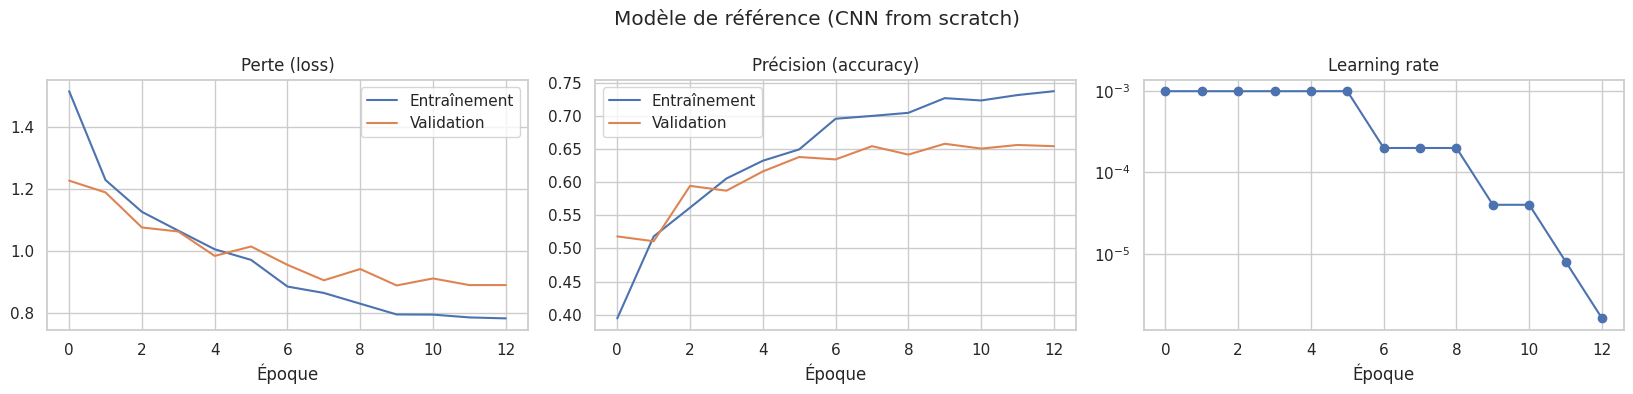

CNN from scratch -> test loss = 0.8242 | test accuracy = 0.6987


In [15]:
plot_history(history_baseline.history, "Modèle de référence (CNN from scratch)")
register_result("CNN from scratch", baseline)

**Analyse du modèle de référence (à commenter avec vos courbes).**
Un petit CNN entraîné depuis zéro sur ~2 500 images apprend des caractéristiques à partir de rien : ses performances sont généralement modestes, et un écart entre la courbe d'entraînement et celle de validation (sur-apprentissage) peut apparaître malgré le Dropout, la L2 et la data augmentation. Le jeu de données est petit par rapport au nombre de paramètres du modèle (la couche dense après `Flatten` en concentre l'essentiel).

---
## 6. Transfert d'apprentissage : ResNet50V2 pré-entraîné

### Pourquoi ResNet50V2 ?

* **Connexions résiduelles** : chaque bloc calcule $y=F(x)+x$. Le gradient peut traverser directement les raccourcis lors de la rétropropagation, ce qui atténue le problème de **disparition du gradient** et permet d'entraîner des réseaux profonds (50 couches).
* **Pré-entraîné sur ImageNet** (1,28 million d'images, 1 000 classes) : les premières couches ont appris des détecteurs génériques (bords, textures, couleurs), utiles pour presque toute tâche visuelle ; les couches profondes ont appris des motifs plus spécifiques.
* Bon compromis taille / performance, très utilisé comme référence.

### Principe du fine-tuning en deux phases

| Phase | Base convolutive | Tête de classification | Learning rate |
|---|---|---|---|
| **1. Extraction de caractéristiques** | gelée (poids non modifiés) | entraînée | $10^{-3}$ |
| **2. Fine-tuning** | dernières couches dégelées | entraînée | $10^{-5}$ |

Entraîner d'abord la tête évite que de gros gradients issus d'une couche initialisée aléatoirement ne détruisent les poids pré-entraînés.

In [16]:
# Chargement de la base pré-entraînée, sans la couche de classification d'origine (include_top=False)
base_model = keras.applications.ResNet50V2(
    include_top=False,
    weights='imagenet',
    input_shape=IMG_SIZE + (3,),
)
base_model.trainable = False       # phase 1 : on gèle toute la base

print("Nombre de couches de la base :", len(base_model.layers))
print("Forme de sortie de la base   :", base_model.output_shape, "(cartes de caractéristiques 7x7, 2048 canaux)")

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Nombre de couches de la base : 190
Forme de sortie de la base   : (None, 7, 7, 2048) (cartes de caractéristiques 7x7, 2048 canaux)


### Construction du modèle complet

```
Entrée (224×224×3)
   → Data augmentation          (actif seulement à l'entraînement)
   → Rescaling [-1, 1]          (prétraitement attendu par ResNet50V2)
   → Base ResNet50V2            (extraction de caractéristiques, training=False)
   → GlobalAveragePooling2D     (7×7×2048  →  vecteur de 2048)
   → Dropout
   → Dense softmax (5 classes)  + régularisation L2
```

Points importants :
* **`GlobalAveragePooling2D`** remplace `Flatten` : on prend la moyenne de chaque carte de caractéristiques. On obtient 2 048 valeurs au lieu de 7×7×2048 = 100 352, donc beaucoup moins de paramètres et moins de sur-apprentissage.
* **`base_model(x, training=False)`** : les couches de **Batch Normalization** de la base restent en mode inférence (elles gardent leurs statistiques apprises sur ImageNet). C'est indispensable, surtout pendant le fine-tuning.
* **Régularisation L2** sur la couche de sortie : on ajoute $\lambda\sum w^2$ à la fonction de coût.

In [17]:
def build_transfer_model():
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1. / 127.5, offset=-1)(x)                 # [0, 255] -> [-1, 1]
    x = base_model(x, training=False)                              # BatchNorm en mode inférence
    x = layers.GlobalAveragePooling2D()(x)                         # (7, 7, 2048) -> (2048,)
    x = layers.Dropout(DROPOUT_RATE)(x)
    outputs = layers.Dense(
        num_classes, activation='softmax',
        kernel_regularizer=regularizers.l2(L2_LAMBDA),
    )(x)
    return keras.Model(inputs, outputs, name="resnet50v2_flowers")

model = build_transfer_model()
compile_model(model, lr=LR_HEAD)
model.summary()

trainable, non_trainable = count_params(model)
print(f"\nParamètres entraînables : {trainable:,}")
print(f"Paramètres figés        : {non_trainable:,}")

Model: "resnet50v2_flowers"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 7, 7, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,575,045 (89.93 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,564,800 (89.89 MB)


Paramètres entraînables : 10,245
Paramètres figés        : 23,564,800


### Phase 1 : entraînement de la tête de classification

Seule la couche Dense finale est entraînée (environ 10 000 paramètres), la base reste figée. L'entraînement est donc rapide.

In [18]:
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=make_callbacks(),
)

Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 21s 181ms/step - accuracy: 0.6423 - loss: 0.9904 - val_accuracy: 0.8091 - val_loss: 0.5129 - learning_rate: 0.0010
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 154ms/step - accuracy: 0.8174 - loss: 0.5127 - val_accuracy: 0.8436 - val_loss: 0.4177 - learning_rate: 0.0010
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 156ms/step - accuracy: 0.8599 - loss: 0.4153 - val_accuracy: 0.8709 - val_loss: 0.3686 - learning_rate: 0.0010
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 156ms/step - accuracy: 0.8591 - loss: 0.3841 - val_accuracy: 0.8691 - val_loss: 0.3582 - learning_rate: 0.0010
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 155ms/step - accuracy: 0.8747 - loss: 0.3514 - val_accuracy: 0.8691 - val_loss: 0.3495 - learning_rate: 0.0010
Epoch 6/10
80/81 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.8810 - loss: 0.3227
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 152ms/step - accuracy: 0.8887 - loss: 0.3

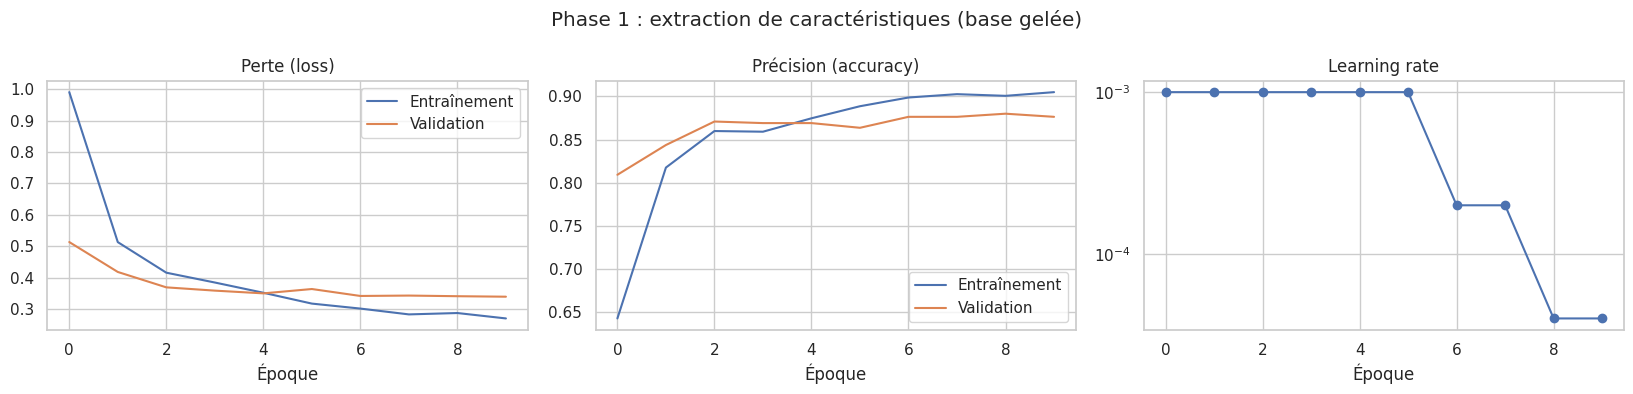

ResNet50V2 : base gelée -> test loss = 0.3081 | test accuracy = 0.8802
Poids de la phase 1 sauvegardés : phase1.weights.h5


In [19]:
plot_history(history_head.history, "Phase 1 : extraction de caractéristiques (base gelée)")
register_result("ResNet50V2 : base gelée", model)

# Sauvegarde des poids après la phase 1 : chaque essai d'optimisation (section 8) repartira de ce point,
# ce qui garantit une comparaison équitable entre les configurations.
PHASE1_WEIGHTS = "phase1.weights.h5"
model.save_weights(PHASE1_WEIGHTS)
print("Poids de la phase 1 sauvegardés :", PHASE1_WEIGHTS)

**Analyse de la phase 1 (à commenter avec vos courbes).**
Avec uniquement la tête entraînée, la précision de validation est déjà nettement supérieure à celle du CNN from scratch : les caractéristiques apprises sur ImageNet se transfèrent bien aux fleurs. La perte de validation peut être inférieure à la perte d'entraînement, car la data augmentation et le Dropout rendent la tâche plus difficile à l'entraînement qu'à la validation.

---
## 7. Phase 2 : Fine-tuning

On **dégèle les dernières couches** de la base (les plus spécialisées) pour les adapter aux fleurs, avec un **learning rate très faible**.

* Les premières couches (bords, textures) restent figées : elles sont génériques.
* Les `FINE_TUNE_LAYERS` dernières couches sont entraînées.
* Les couches **BatchNormalization** restent figées, même dans la partie dégelée (pratique recommandée pour la stabilité).
* Il faut **recompiler** le modèle après tout changement de `trainable`.

In [20]:
def set_trainable_layers(n_layers):
    """Dégèle les n_layers dernières couches de la base (les couches BatchNorm restent toujours figées)."""
    base_model.trainable = True
    fine_tune_at = len(base_model.layers) - n_layers

    # 1) On regèle toutes les couches avant 'fine_tune_at'
    for layer in base_model.layers[:fine_tune_at]:
        layer.trainable = False

    # 2) Dans la partie dégelée, on garde les BatchNorm figées
    for layer in base_model.layers[fine_tune_at:]:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    return fine_tune_at

fine_tune_at = set_trainable_layers(FINE_TUNE_LAYERS)
print(f"On dégèle à partir de la couche {fine_tune_at} sur {len(base_model.layers)}")

# Recompilation obligatoire avec un learning rate beaucoup plus faible
compile_model(model, lr=LR_FT)

trainable, non_trainable = count_params(model)
print(f"Paramètres entraînables : {trainable:,}")
print(f"Paramètres figés        : {non_trainable:,}")

On dégèle à partir de la couche 160 sur 190
Paramètres entraînables : 14,436,357
Paramètres figés        : 9,138,688


In [21]:
initial_epoch = len(history_head.history['loss'])    # on reprend la numérotation après la phase 1

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=initial_epoch,
    epochs=initial_epoch + EPOCHS_FT,
    callbacks=make_callbacks(),
)

Epoch 11/25
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 217ms/step - accuracy: 0.9046 - loss: 0.2651 - val_accuracy: 0.8855 - val_loss: 0.3059 - learning_rate: 1.0000e-05
Epoch 12/25
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 195ms/step - accuracy: 0.9268 - loss: 0.2090 - val_accuracy: 0.8964 - val_loss: 0.2786 - learning_rate: 1.0000e-05
Epoch 13/25
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 193ms/step - accuracy: 0.9389 - loss: 0.1750 - val_accuracy: 0.9055 - val_loss: 0.2600 - learning_rate: 1.0000e-05
Epoch 14/25
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 191ms/step - accuracy: 0.9533 - loss: 0.1431 - val_accuracy: 0.9091 - val_loss: 0.2518 - learning_rate: 1.0000e-05
Epoch 15/25
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.9463 - loss: 0.1470
Epoch 15: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 189ms/step - accuracy: 0.9552 - loss: 0.1271 - val_accuracy: 0.9073 - val_loss: 0.2537 - learning_rate: 1.0000e-05
Epoch 16/25
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 192ms/step - a

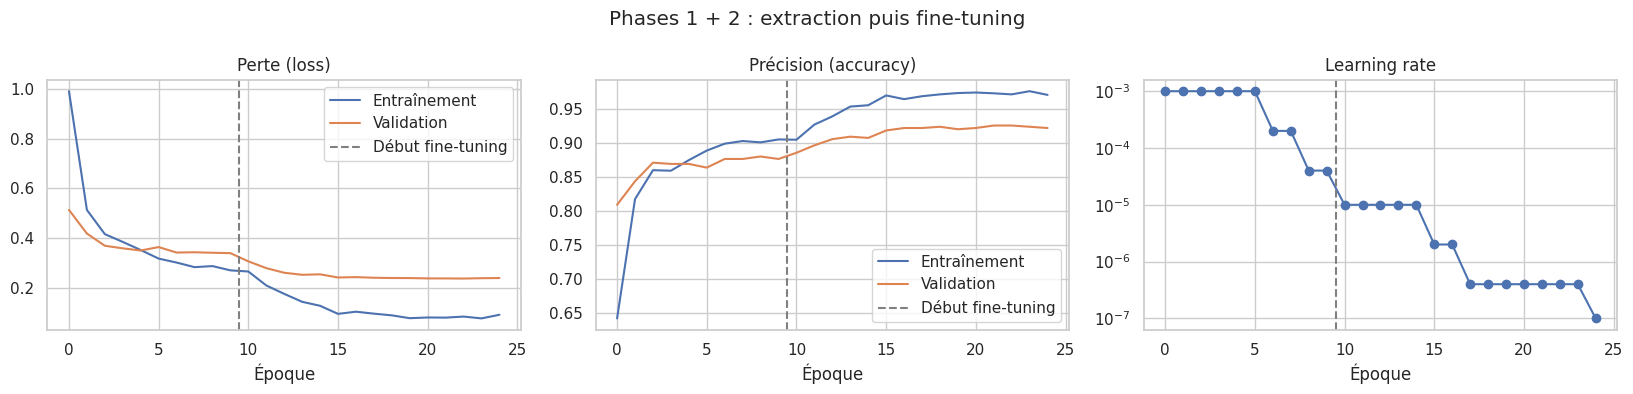

ResNet50V2 : fine-tuning -> test loss = 0.2252 | test accuracy = 0.9292
Configuration par défaut -> val loss = 0.2367 | val accuracy = 0.9255


In [22]:
history_all = merge_histories(history_head, history_ft)
plot_history(history_all, "Phases 1 + 2 : extraction puis fine-tuning", boundary=initial_epoch)
register_result("ResNet50V2 : fine-tuning", model)

# Sauvegarde de la configuration par défaut, pour la comparer plus tard à la configuration optimisée (section 8.5)
DEFAULT_FT_WEIGHTS = "finetune_default.weights.h5"
model.save_weights(DEFAULT_FT_WEIGHTS)
val_loss_default, val_acc_default = model.evaluate(val_ds, verbose=0)
print(f"Configuration par défaut -> val loss = {val_loss_default:.4f} | val accuracy = {val_acc_default:.4f}")

**Analyse du fine-tuning (à commenter avec vos courbes).**
Au début de la phase 2, la perte de validation doit continuer à baisser légèrement, puis se stabiliser. Le gain de précision par rapport à la phase 1 est en général modeste mais réel (quelques points) : les dernières couches se spécialisent sur les textures et formes propres aux fleurs. Le `ReduceLROnPlateau` (courbe du learning rate) et l'`EarlyStopping` empêchent de surentraîner : les poids retenus sont ceux de la meilleure époque. Un fine-tuning avec un learning rate trop élevé ferait au contraire remonter la perte (oubli catastrophique des poids pré-entraînés).

---
## 8. Optimisation des hyperparamètres du fine-tuning

### 8.1 Pourquoi et comment optimiser ?

* **Paramètres** : poids et biais, appris automatiquement par rétropropagation.
* **Hyperparamètres** : réglages fixés **avant** l'entraînement (learning rate, nombre de couches dégelées, dropout, $\lambda$, taille de batch, nombre d'époques...). Ils ne sont pas appris par le gradient : il faut les chercher.

Jusqu'ici, `LR_FT = 1e-5` et `FINE_TUNE_LAYERS = 30` étaient des choix raisonnés. On les **valide maintenant de façon systématique**, avec les méthodes vues dans les labs d'optimisation.

| Méthode | Principe | Avantages | Limites |
|---|---|---|---|
| **Grid Search** | Teste **toutes** les combinaisons d'une grille de valeurs | Exhaustif, reproductible, lecture facile des résultats | Le coût explose avec le nombre d'hyperparamètres ($n^k$ essais) |
| **Random Search** | Tire des combinaisons **au hasard** dans des distributions | Explore plus de valeurs différentes pour chaque hyperparamètre avec le même budget ; efficace quand seuls quelques hyperparamètres comptent vraiment | Peut manquer la meilleure zone ; résultats dépendants de la graine |

### Protocole utilisé

1. Hyperparamètres explorés : **learning rate du fine-tuning**, **nombre de couches dégelées**, **dropout**.
2. Chaque essai **repart des mêmes poids** (fin de la phase 1) : la comparaison est équitable.
3. Essais **courts** (`SEARCH_EPOCHS` époques) avec early stopping, pour limiter le coût.
4. Score = **précision sur le jeu de validation**, mesurée avec les poids de la meilleure `val_loss`. Le jeu de **test n'est jamais utilisé** pour choisir.
5. La meilleure configuration est ensuite réentraînée complètement et comparée à la configuration par défaut.

### Points d'attention par rapport aux labs

* **Wrapper `KerasClassifier`** (lab *GridSearch / RandomizedSearchCV*) : le module `tensorflow.keras.wrappers.scikit_learn` a été **supprimé depuis TensorFlow 2.12** (le lab affichait pourtant TensorFlow 2.17). Son successeur est la bibliothèque **SciKeras**, utilisée en section 8.4. La validation croisée (cv=3) sur un ResNet50 complet serait trop coûteuse : on l'applique donc à la tête de classification, et on utilise des boucles manuelles avec jeu de validation pour le fine-tuning complet (démarche du lab *optimisation manuelle*).
* **Score `max(val_accuracy)` sur toutes les époques** (lab manuel) : mesure optimiste, car on retient la meilleure époque *a posteriori* de façon sélective. Ici on restaure les poids de la meilleure `val_loss` puis on mesure.
* **Nombre d'époques comme hyperparamètre** : remplacé par l'**early stopping**, qui l'ajuste automatiquement.
* **Tirage du learning rate** : l'effet d'un learning rate est multiplicatif ; on le tire donc en **échelle logarithmique**, $\eta=10^{u}$ avec $u\sim\mathcal U(-6,-3)$. Un tirage uniforme sur $[10^{-4},10^{-2}]$ (comme dans le lab) place environ 90 % des valeurs au-dessus de $10^{-3}$ et explore très mal les petites valeurs, pourtant essentielles en fine-tuning.

In [23]:
import itertools
import time

# Couche Dropout du modèle : on pourra modifier son taux à chaque essai
dropout_layer = [l for l in model.layers if isinstance(l, layers.Dropout)][0]

def run_trial(lr, n_layers, dropout, epochs=None):
    """Un essai d'optimisation : repart des poids de la phase 1, fine-tune brièvement, mesure sur la validation."""
    epochs = epochs or SEARCH_EPOCHS

    model.load_weights(PHASE1_WEIGHTS)          # même point de départ pour tous les essais
    set_trainable_layers(n_layers)              # nombre de couches dégelées
    dropout_layer.rate = dropout                # taux de dropout
    compile_model(model, lr)                    # recompilation (nouveau learning rate)

    early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     callbacks=[early_stop], verbose=0)

    # Les poids de la meilleure val_loss ont été restaurés : on mesure la validation avec ces poids
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    return {"lr": lr, "n_layers": n_layers, "dropout": dropout,
            "val_loss": val_loss, "val_acc": val_acc, "epochs_run": len(hist.history['loss'])}

print("Couche Dropout trouvée :", dropout_layer.name)
print("Nombre de combinaisons du Grid Search :", len(GRID_LRS) * len(GRID_LAYERS))
print("Nombre d'essais du Random Search      :", N_RANDOM_TRIALS)

Couche Dropout trouvée : dropout_1
Nombre de combinaisons du Grid Search : 9
Nombre d'essais du Random Search      : 6


### 8.2 Grid Search (recherche exhaustive)

Grille : learning rate $\in\{10^{-4},10^{-5},10^{-6}\}$ × nombre de couches dégelées $\in\{10,30,60\}$, soit **9 combinaisons**. Le dropout est fixé à `DROPOUT_RATE` pour garder une grille en deux dimensions, lisible sous forme de carte de chaleur.

In [24]:
grid_records = []

if RUN_SEARCH:
    grid = list(itertools.product(GRID_LRS, GRID_LAYERS))
    for k, (lr, n_layers) in enumerate(grid, 1):
        t0 = time.time()
        rec = run_trial(lr, n_layers, DROPOUT_RATE)
        grid_records.append(rec)
        print(f"[{k}/{len(grid)}] lr={lr:.0e} | couches dégelées={n_layers:>2} | "
              f"val_acc={rec['val_acc']:.4f} | val_loss={rec['val_loss']:.4f} | {time.time() - t0:.0f}s")
else:
    print("Grid Search ignoré (RUN_SEARCH = False)")

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 32 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


[1/9] lr=1e-04 | couches dégelées=10 | val_acc=0.8873 | val_loss=0.2847 | 51s


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 12 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


[2/9] lr=1e-04 | couches dégelées=30 | val_acc=0.8855 | val_loss=0.2950 | 50s
[3/9] lr=1e-04 | couches dégelées=60 | val_acc=0.8855 | val_loss=0.3255 | 50s
[4/9] lr=1e-05 | couches dégelées=10 | val_acc=0.8782 | val_loss=0.3152 | 50s
[5/9] lr=1e-05 | couches dégelées=30 | val_acc=0.8909 | val_loss=0.3202 | 50s
[6/9] lr=1e-05 | couches dégelées=60 | val_acc=0.8836 | val_loss=0.3227 | 51s
[7/9] lr=1e-06 | couches dégelées=10 | val_acc=0.8782 | val_loss=0.3360 | 50s
[8/9] lr=1e-06 | couches dégelées=30 | val_acc=0.8745 | val_loss=0.3351 | 50s
[9/9] lr=1e-06 | couches dégelées=60 | val_acc=0.8800 | val_loss=0.3344 | 52s


,lr,n_layers,dropout,val_loss,val_acc,epochs_run
0,0.000010,30,0.3,0.320236,0.890909,3
1,0.000100,10,0.3,0.284698,0.887273,3
2,0.000100,30,0.3,0.294969,0.885455,3
3,0.000100,60,0.3,0.325470,0.885455,3
4,0.000010,60,0.3,0.322663,0.883636,3
5,0.000001,60,0.3,0.334360,0.880000,3
6,0.000010,10,0.3,0.315184,0.878182,3
7,0.000001,10,0.3,0.336041,0.878182,3
8,0.000001,30,0.3,0.335130,0.874545,3


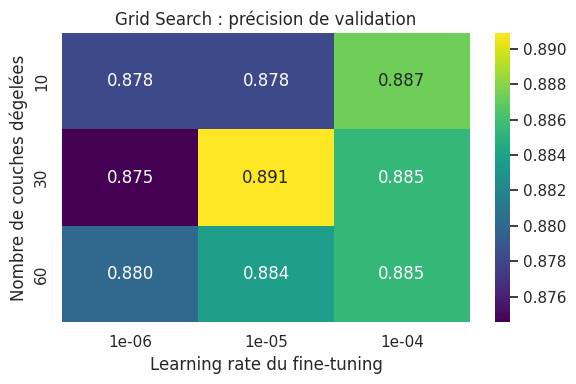

In [25]:
if grid_records:
    df_grid = pd.DataFrame(grid_records)
    display(df_grid.sort_values(["val_acc", "val_loss"], ascending=[False, True]).reset_index(drop=True))

    pivot = df_grid.pivot(index="n_layers", columns="lr", values="val_acc")
    pivot.columns = [f"{c:.0e}" for c in pivot.columns]

    plt.figure(figsize=(6, 4))
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
    plt.title("Grid Search : précision de validation")
    plt.xlabel("Learning rate du fine-tuning")
    plt.ylabel("Nombre de couches dégelées")
    plt.tight_layout()
    plt.show()

**Analyse du Grid Search (à commenter avec votre carte de chaleur).**
On lit directement l'effet de chaque hyperparamètre : un learning rate trop élevé dégrade les poids pré-entraînés, alors qu'un learning rate trop faible apprend trop lentement en quelques époques. Le nombre de couches dégelées modifie la capacité d'adaptation du modèle : trop peu limite l'adaptation, beaucoup de couches augmente le risque de sur-apprentissage et le temps de calcul. Si plusieurs cases ont des scores très proches, la différence n'est probablement pas significative (la validation ne contient que ~550 images).

### 8.3 Random Search (recherche aléatoire)

Chaque essai tire :
* le learning rate en échelle logarithmique : $10^{u},\ u\sim\mathcal U(-6,-3)$ ;
* le nombre de couches dégelées parmi $\{10,20,30,50,80\}$ ;
* le dropout uniformément dans $[0.2,\,0.5]$.

Avec 6 essais seulement, le Random Search teste 6 valeurs **différentes** de chaque hyperparamètre, alors que la grille n'en teste que 3 par hyperparamètre pour 9 essais.

In [26]:
rng = np.random.default_rng(SEED)      # graine fixée pour la reproductibilité
random_records = []

if RUN_SEARCH:
    for k in range(1, N_RANDOM_TRIALS + 1):
        lr = float(10 ** rng.uniform(-6, -3))                    # tirage log-uniforme
        n_layers = int(rng.choice([10, 20, 30, 50, 80]))
        dropout = float(rng.uniform(0.2, 0.5))

        t0 = time.time()
        rec = run_trial(lr, n_layers, dropout)
        random_records.append(rec)
        print(f"[{k}/{N_RANDOM_TRIALS}] lr={lr:.2e} | couches={n_layers:>2} | dropout={dropout:.2f} | "
              f"val_acc={rec['val_acc']:.4f} | val_loss={rec['val_loss']:.4f} | {time.time() - t0:.0f}s")
else:
    print("Random Search ignoré (RUN_SEARCH = False)")

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 12 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


[1/6] lr=2.10e-04 | couches=50 | dropout=0.46 | val_acc=0.8800 | val_loss=0.2812 | 51s
[2/6] lr=1.24e-04 | couches=30 | dropout=0.23 | val_acc=0.8836 | val_loss=0.3133 | 50s
[3/6] lr=8.45e-04 | couches=50 | dropout=0.44 | val_acc=0.8764 | val_loss=0.3005 | 50s
[4/6] lr=2.42e-06 | couches=50 | dropout=0.34 | val_acc=0.8782 | val_loss=0.3310 | 50s
[5/6] lr=1.30e-05 | couches=10 | dropout=0.39 | val_acc=0.8927 | val_loss=0.3120 | 52s
[6/6] lr=2.94e-04 | couches=80 | dropout=0.33 | val_acc=0.8836 | val_loss=0.2950 | 50s


,lr,n_layers,dropout,val_loss,val_acc,epochs_run
0,0.000013,10,0.393160,0.312014,0.892727,3
1,0.000294,80,0.333024,0.294952,0.883636,3
2,0.000124,30,0.228253,0.313260,0.883636,3
3,0.000210,50,0.457579,0.281187,0.880000,3
4,0.000002,50,0.335116,0.330998,0.878182,3
5,0.000845,50,0.435819,0.300527,0.876364,3


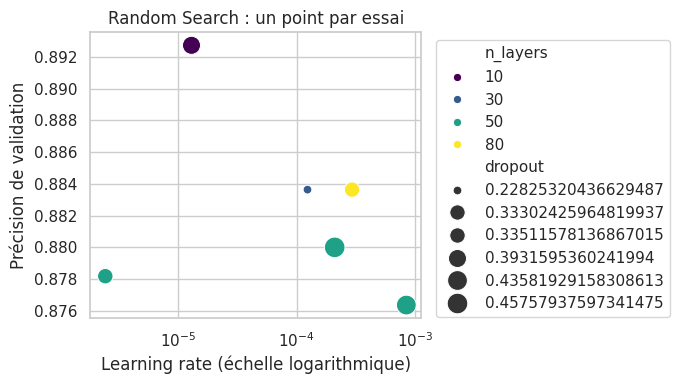

In [27]:
if random_records:
    df_random = pd.DataFrame(random_records)
    display(df_random.sort_values(["val_acc", "val_loss"], ascending=[False, True]).reset_index(drop=True))

    plt.figure(figsize=(7, 4))
    sns.scatterplot(data=df_random, x="lr", y="val_acc", hue="n_layers",
                    size="dropout", sizes=(40, 220), palette="viridis")
    plt.xscale("log")
    plt.xlabel("Learning rate (échelle logarithmique)")
    plt.ylabel("Précision de validation")
    plt.title("Random Search : un point par essai")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

**Analyse du Random Search (à commenter avec votre graphique).**
Chaque point correspond à un essai. On regarde si la précision dépend surtout du learning rate (tendance le long de l'axe horizontal), du nombre de couches (couleur) ou du dropout (taille). Comparez ensuite avec le Grid Search : si le Random Search atteint un score voisin avec moins d'essais, cela illustre son intérêt ; s'il est moins bon, c'est la limite d'un tirage sur très peu d'essais.

### 8.4 Wrapper scikit-learn : `GridSearchCV` et `RandomizedSearchCV` avec validation croisée

Cette approche, vue dans le lab sur les wrappers, encapsule un modèle Keras dans un objet compatible scikit-learn (ici **SciKeras**, qui remplace l'ancien `KerasClassifier`) pour utiliser `GridSearchCV` et `RandomizedSearchCV`, avec **validation croisée à 3 plis**.

Comme une validation croisée sur le ResNet complet nécessiterait 3 entraînements par combinaison, on l'applique ici à la **tête de classification** seulement :

1. On **extrait une fois** les caractéristiques de la base gelée (vecteurs de 2 048 valeurs après `GlobalAveragePooling2D`) ;
2. on règle le **Dropout, le coefficient $\lambda$ de la L2, le learning rate et la taille de batch** d'un classifieur softmax sur ces vecteurs : chaque entraînement ne dure que quelques secondes.

Remarque : cette expérience n'utilise pas la data augmentation (les caractéristiques sont extraites une seule fois). Elle donne une indication sur la sensibilité de la tête à ces hyperparamètres.

In [44]:
wrapper_ok = False
if RUN_WRAPPER_SEARCH:
    try:
        import scikeras
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "scikeras"])
    try:
        from scikeras.wrappers import KerasClassifier
        from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
        wrapper_ok = True
    except Exception as e:
        print("SciKeras indisponible, section ignorée :", e)

if wrapper_ok:
    # Retour aux poids de la phase 1 : la base est dans son état pré-entraîné (ImageNet)
    model.load_weights(PHASE1_WEIGHTS)

    # Extracteur de caractéristiques : base ResNet + GlobalAveragePooling2D
    feature_model = keras.Model(base_model.input,
                                layers.GlobalAveragePooling2D()(base_model.output))

    def extract_features(ds):
        feats, labs = [], []
        for x, y in ds:
            feats.append(feature_model(x / 127.5 - 1.0, training=False).numpy())  # même prétraitement que le modèle
            labs.append(np.argmax(y.numpy(), axis=1))
        return np.concatenate(feats), np.concatenate(labs)

    X_tr, y_tr = extract_features(train_ds)
    X_va, y_va = extract_features(val_ds)
    print("Caractéristiques d'entraînement :", X_tr.shape, "| validation :", X_va.shape)

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 12 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Caractéristiques d'entraînement : (2569, 2048) | validation : (550, 2048)


In [47]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils import ClassifierTags

# Correctif : ClassifierMixin tolère l'ordre d'héritage de SciKeras
if not getattr(ClassifierMixin, "_patched_tags", False):
    _orig_tags = ClassifierMixin.__sklearn_tags__

    def _safe_tags(self):
        try:
            return _orig_tags(self)
        except AttributeError:
            tags = BaseEstimator.__sklearn_tags__(self)
            tags.estimator_type = "classifier"
            tags.classifier_tags = ClassifierTags()
            return tags

    ClassifierMixin.__sklearn_tags__ = _safe_tags
    ClassifierMixin._patched_tags = True
print("Correctif appliqué")

Correctif appliqué


In [52]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

class KerasHeadClassifier(ClassifierMixin, BaseEstimator):   # ClassifierMixin AVANT BaseEstimator
    """Tête de classification Keras (Dropout + Dense softmax + L2), compatible scikit-learn."""
    def __init__(self, dropout_rate=0.3, l2_lambda=1e-4, learning_rate=1e-3,
                 batch_size=32, epochs=15):
        self.dropout_rate = dropout_rate
        self.l2_lambda = l2_lambda
        self.learning_rate = learning_rate
        self.batch_size = batch_size
        self.epochs = epochs

    def fit(self, X, y):
        X = np.asarray(X, dtype="float32")
        self.classes_ = np.unique(y)
        y_idx = np.searchsorted(self.classes_, y)             # étiquettes entières 0..K-1
        self.model_ = keras.Sequential([
            layers.Input(shape=(X.shape[1],)),
            layers.Dropout(self.dropout_rate),
            layers.Dense(len(self.classes_), activation="softmax",
                         kernel_regularizer=regularizers.l2(self.l2_lambda)),
        ])
        self.model_.compile(optimizer=keras.optimizers.Adam(self.learning_rate),
                            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        self.model_.fit(X, y_idx, epochs=self.epochs, batch_size=self.batch_size, verbose=0)
        return self

    def predict_proba(self, X):
        return self.model_.predict(np.asarray(X, dtype="float32"), verbose=0)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

# Référence : tête avec les hyperparamètres par défaut
clf = KerasHeadClassifier()
clf.fit(X_tr, y_tr)
acc_default_head = clf.score(X_va, y_va)
print(f"Tête par défaut -> précision de validation = {acc_default_head:.4f}")

# ----- Grid Search avec validation croisée (3 plis) -----
param_grid = {
    "dropout_rate": [0.2, 0.5, 0.7],
    "l2_lambda": [1e-5, 1e-3, 1e-2],
}
grid_cv = GridSearchCV(clf, param_grid, cv=3, scoring="accuracy", n_jobs=1, verbose=1)
grid_cv.fit(X_tr, y_tr)
print("\nGridSearchCV -> meilleurs hyperparamètres :", grid_cv.best_params_)
print(f"Score de validation croisée : {grid_cv.best_score_:.4f}")
print(f"Précision sur la validation : {grid_cv.best_estimator_.score(X_va, y_va):.4f}")

Tête par défaut -> précision de validation = 0.8873
Fitting 3 folds for each of 9 candidates, totalling 27 fits

GridSearchCV -> meilleurs hyperparamètres : {'dropout_rate': 0.2, 'l2_lambda': 0.01}
Score de validation croisée : 0.8821
Précision sur la validation : 0.8745


In [53]:
param_dist = {
    "dropout_rate": [0.2, 0.3, 0.5, 0.7],
    "l2_lambda": [1e-5, 1e-4, 1e-3, 1e-2],
    "learning_rate": [1e-4, 3e-4, 1e-3, 1e-2],
    "batch_size": [16, 32, 64],
}
random_cv = RandomizedSearchCV(clf, param_dist, n_iter=10, cv=3, scoring="accuracy",
                               random_state=SEED, n_jobs=1, verbose=1)
random_cv.fit(X_tr, y_tr)
print("\nRandomizedSearchCV -> meilleurs hyperparamètres :", random_cv.best_params_)
print(f"Score de validation croisée : {random_cv.best_score_:.4f}")
print(f"Précision sur la validation : {random_cv.best_estimator_.score(X_va, y_va):.4f}")

cv_table = pd.DataFrame(random_cv.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
display(cv_table.sort_values("rank_test_score").head(5))

Fitting 3 folds for each of 10 candidates, totalling 30 fits

RandomizedSearchCV -> meilleurs hyperparamètres : {'learning_rate': 0.001, 'l2_lambda': 1e-05, 'dropout_rate': 0.3, 'batch_size': 16}
Score de validation croisée : 0.8758
Précision sur la validation : 0.8964


,params,mean_test_score,std_test_score,rank_test_score
7,"{'learning_rate': 0.001, 'l2_lambda': 1e-05, '...",0.875825,0.006388,1
9,"{'learning_rate': 0.0003, 'l2_lambda': 0.001, ...",0.874271,0.006756,2
0,"{'learning_rate': 0.0003, 'l2_lambda': 0.01, '...",0.872712,0.008755,3
4,"{'learning_rate': 0.0003, 'l2_lambda': 1e-05, ...",0.852862,0.009373,4
3,"{'learning_rate': 0.01, 'l2_lambda': 0.01, 'dr...",0.851694,0.012898,5


**Analyse (à commenter avec vos résultats).**
La validation croisée donne, pour chaque combinaison, une **moyenne** et un **écart-type** de la précision sur 3 plis : c'est une estimation plus fiable qu'un seul découpage. Comparez la précision de la tête par défaut avec celles des meilleures configurations. Sur ce problème, les caractéristiques d'ImageNet sont déjà très discriminantes : on s'attend à des écarts faibles entre configurations, ce qui indique que la tête est peu sensible à ces hyperparamètres.

### 8.5 Fine-tuning final avec la meilleure configuration

On retient la **meilleure combinaison** (précision de validation) parmi les essais du Grid Search et du Random Search, puis on refait un fine-tuning **complet** (jusqu'à `EPOCHS_FT` époques, avec early stopping et learning rate adaptatif). On compare enfin le résultat à la configuration par défaut **sur la validation** : le modèle conservé pour l'évaluation finale est celui qui a la meilleure précision de validation. Si l'optimisation n'apporte pas de gain, garder la configuration par défaut est une conclusion tout à fait valable.

In [54]:
# ----- Choix de la meilleure configuration -----
all_records = ([dict(r, method="Grid Search") for r in grid_records] +
               [dict(r, method="Random Search") for r in random_records])

if all_records:
    df_all = (pd.DataFrame(all_records)
              .sort_values(["val_acc", "val_loss"], ascending=[False, True])
              .reset_index(drop=True))
    print("Meilleur score par méthode :")
    display(df_all.groupby("method")[["val_acc"]].max())
    print("Top 5 des configurations :")
    display(df_all.head(5))
    best_cfg = {"lr": float(df_all.loc[0, "lr"]),
                "n_layers": int(df_all.loc[0, "n_layers"]),
                "dropout": float(df_all.loc[0, "dropout"])}
else:
    print("Aucun essai disponible : on garde la configuration par défaut.")
    best_cfg = {"lr": LR_FT, "n_layers": FINE_TUNE_LAYERS, "dropout": DROPOUT_RATE}

print("\nConfiguration retenue :", best_cfg)

# ----- Fine-tuning complet avec cette configuration -----
model.load_weights(PHASE1_WEIGHTS)
dropout_layer.rate = best_cfg["dropout"]
set_trainable_layers(best_cfg["n_layers"])
compile_model(model, best_cfg["lr"])

history_opt = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FT,
    callbacks=make_callbacks(),
)

Meilleur score par méthode :


,val_acc
method,
Grid Search,0.890909
Random Search,0.892727


Top 5 des configurations :


,lr,n_layers,dropout,val_loss,val_acc,epochs_run,method
0,0.000013,10,0.39316,0.312014,0.892727,3,Random Search
1,0.000010,30,0.30000,0.320236,0.890909,3,Grid Search
2,0.000100,10,0.30000,0.284698,0.887273,3,Grid Search
3,0.000100,30,0.30000,0.294969,0.885455,3,Grid Search
4,0.000100,60,0.30000,0.325470,0.885455,3,Grid Search



Configuration retenue : {'lr': 1.2953707094821835e-05, 'n_layers': 10, 'dropout': 0.3931595360241994}
Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 12 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


81/81 ━━━━━━━━━━━━━━━━━━━━ 22s 194ms/step - accuracy: 0.8984 - loss: 0.2967 - val_accuracy: 0.8709 - val_loss: 0.3306 - learning_rate: 1.2954e-05
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 14s 167ms/step - accuracy: 0.9019 - loss: 0.2848 - val_accuracy: 0.8855 - val_loss: 0.3169 - learning_rate: 1.2954e-05
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.9150 - loss: 0.2603
Epoch 3: ReduceLROnPlateau reducing learning rate to 2.5907414965331558e-06.
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 161ms/step - accuracy: 0.9031 - loss: 0.2789 - val_accuracy: 0.8818 - val_loss: 0.3180 - learning_rate: 1.2954e-05
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 161ms/step - accuracy: 0.9039 - loss: 0.2759 - val_accuracy: 0.8800 - val_loss: 0.3128 - learning_rate: 2.5907e-06
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 162ms/step - accuracy: 0.9136 - loss: 0.2492 - val_accuracy: 0.8800 - val_loss: 0.3095 - learning_rate: 2.5907e-06
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.9122 - l

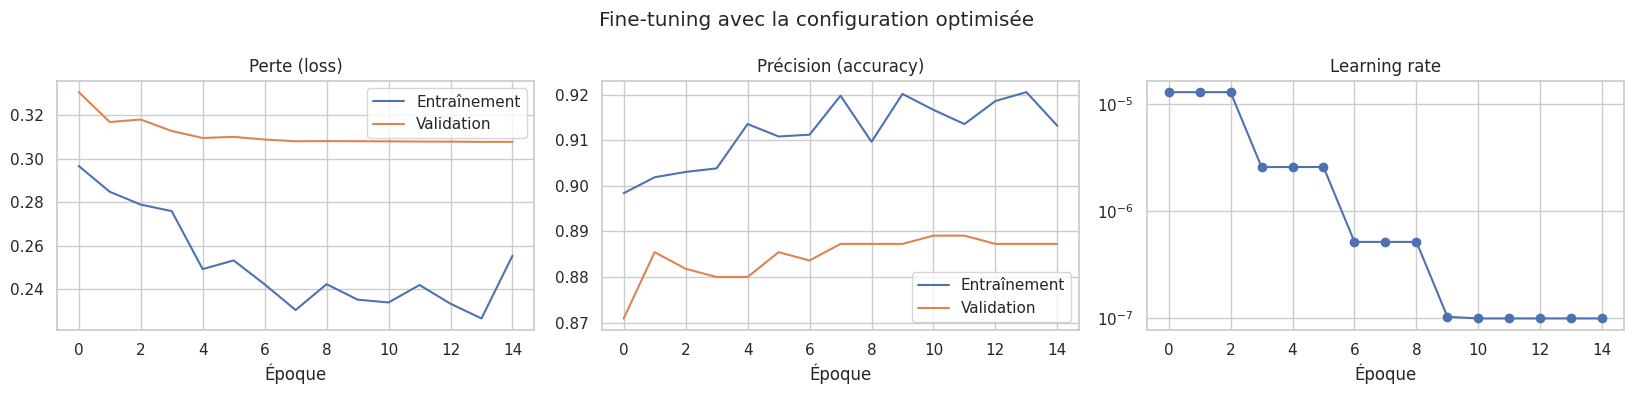

ResNet50V2 : fine-tuning optimisé -> test loss = 0.2838 | test accuracy = 0.8893

Validation : configuration par défaut  -> accuracy = 0.9255
Validation : configuration optimisée   -> accuracy = 0.8873
Modèle retenu pour l'évaluation finale : configuration par défaut


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 12 variables whereas the saved optimizer has 32 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [55]:
plot_history(history_opt.history, "Fine-tuning avec la configuration optimisée")
register_result("ResNet50V2 : fine-tuning optimisé", model)

# ----- Sélection du modèle final sur la VALIDATION (pas sur le test) -----
val_loss_opt, val_acc_opt = model.evaluate(val_ds, verbose=0)
print(f"\nValidation : configuration par défaut  -> accuracy = {val_acc_default:.4f}")
print(f"Validation : configuration optimisée   -> accuracy = {val_acc_opt:.4f}")

if val_acc_opt >= val_acc_default:
    final_choice = "configuration optimisée"
else:
    model.load_weights(DEFAULT_FT_WEIGHTS)       # on revient aux poids de la configuration par défaut
    final_choice = "configuration par défaut"
print("Modèle retenu pour l'évaluation finale :", final_choice)

**Analyse de l'optimisation (à commenter avec vos résultats).**
Comparez la précision de validation de la configuration par défaut et de la configuration optimisée. Un gain faible (de l'ordre de la variabilité d'une exécution à l'autre) signifie que la configuration raisonnée de départ était déjà bonne : l'optimisation a alors surtout servi à **le vérifier**. Un gain net montre l'importance du learning rate et du nombre de couches dégelées en fine-tuning. Rappel méthodologique : la sélection a été faite sur la validation ; le jeu de test reste réservé à l'estimation finale de la performance.

---
## 9. Visualisation des filtres et des cartes de caractéristiques

Cette section illustre les notions de **filtre (noyau)** et de **feature map** :

* les filtres de la première couche sont de petites matrices de poids ($7\times7\times3$) qui détectent des motifs simples (bords, couleurs) ;
* plus on avance dans le réseau, plus les cartes de caractéristiques sont petites (réduction par stride et pooling) et plus elles représentent des motifs abstraits.

Nombre de couches de convolution dans ResNet50V2 : 53
Forme des filtres de la 1ère couche : (7, 7, 3, 64)


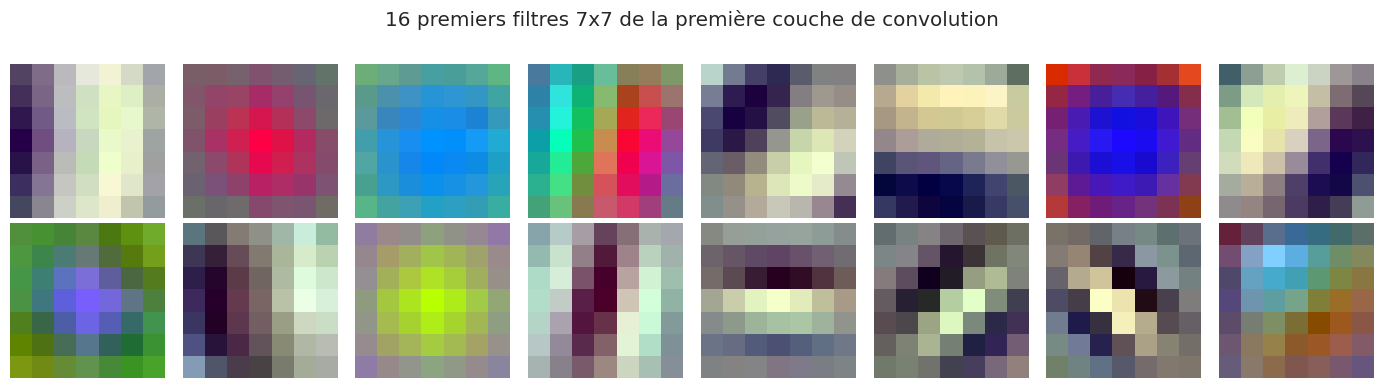

In [56]:
conv_layers = [l for l in base_model.layers if isinstance(l, layers.Conv2D)]
print("Nombre de couches de convolution dans ResNet50V2 :", len(conv_layers))

# --- Filtres de la première couche de convolution ---
kernels = conv_layers[0].get_weights()[0]          # forme (7, 7, 3, 64) : hauteur, largeur, canaux, nb de filtres
print("Forme des filtres de la 1ère couche :", kernels.shape)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    k = kernels[:, :, :, i]
    k = (k - k.min()) / (k.max() - k.min() + 1e-8)  # normalisation pour l'affichage
    ax.imshow(k)
    ax.axis('off')
plt.suptitle("16 premiers filtres 7x7 de la première couche de convolution")
plt.tight_layout()
plt.show()

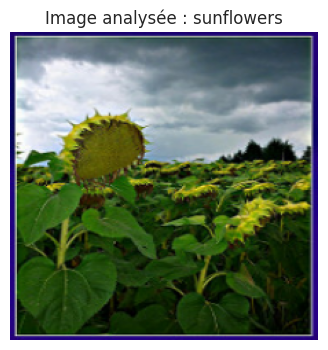

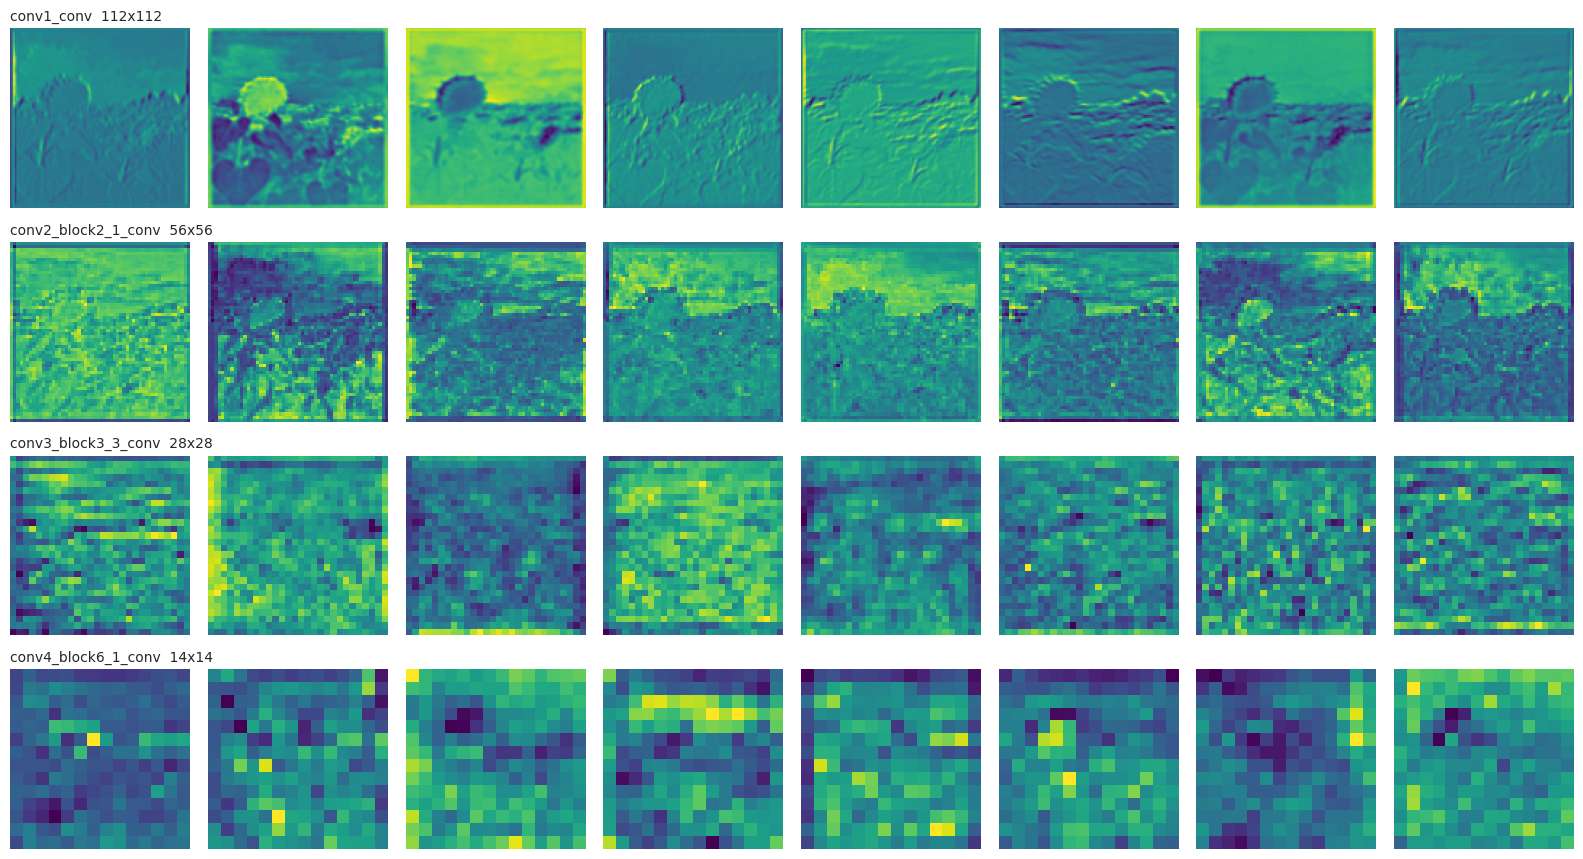

In [57]:
# --- Cartes de caractéristiques à différentes profondeurs ---
selected_idx = [0, 5, 20, 40]                       # du début à la fin du réseau
selected_layers = [conv_layers[i] for i in selected_idx]

feature_extractor = keras.Model(
    inputs=base_model.input,
    outputs=[l.output for l in selected_layers],
)

# On prend une image du jeu de test et on applique le même prétraitement que le modèle
test_images, test_labels = next(iter(test_ds))
image = test_images[0].numpy()
x = (image[None, ...] / 127.5) - 1.0
feature_maps = feature_extractor.predict(x, verbose=0)

plt.figure(figsize=(4, 4))
plt.imshow(image.astype("uint8"))
plt.title(f"Image analysée : {class_names[int(np.argmax(test_labels[0]))]}")
plt.axis('off')
plt.show()

n_maps = 8
fig, axes = plt.subplots(len(selected_layers), n_maps, figsize=(16, 2.2 * len(selected_layers)))
for row, (layer, fmap) in enumerate(zip(selected_layers, feature_maps)):
    for col in range(n_maps):
        axes[row, col].imshow(fmap[0, :, :, col], cmap='viridis')
        axes[row, col].axis('off')
    axes[row, 0].set_title(f"{layer.name}  {fmap.shape[1]}x{fmap.shape[2]}", loc='left', fontsize=10)
plt.tight_layout()
plt.show()

**Observation.** Dans les premières couches, les cartes ressemblent encore à l'image (bords, contrastes) avec une résolution élevée. Plus en profondeur, la résolution spatiale diminue (stride et pooling) et les cartes deviennent plus abstraites, moins interprétables visuellement : elles encodent la présence de motifs complexes (pétales, textures, centres de fleurs).

---
## 10. Évaluation finale du modèle retenu

Le modèle évalué ici est celui retenu en section 8.5 (meilleure précision de validation entre la configuration par défaut et la configuration optimisée). On l'évalue sur le **jeu de test** (jamais utilisé pendant l'entraînement ni pour régler les hyperparamètres) :

* **accuracy** globale ;
* **précision, rappel, F1** par classe (`classification_report`) ;
* **matrice de confusion** : montre quelles classes sont confondues ;
* **analyse des erreurs** : images mal classées et niveau de confiance du modèle.

In [58]:
# Étiquettes réelles et prédictions (test_ds n'est pas mélangé : l'ordre est stable)
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])
y_proba = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_proba, axis=1)          # classe de probabilité maximale

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

              precision    recall  f1-score   support

       daisy      0.941     0.952     0.947        84
   dandelion      0.930     0.950     0.940       139
       roses      0.890     0.900     0.895        90
  sunflowers      0.956     0.948     0.952       115
      tulips      0.924     0.894     0.909       123

    accuracy                          0.929       551
   macro avg      0.928     0.929     0.928       551
weighted avg      0.929     0.929     0.929       551



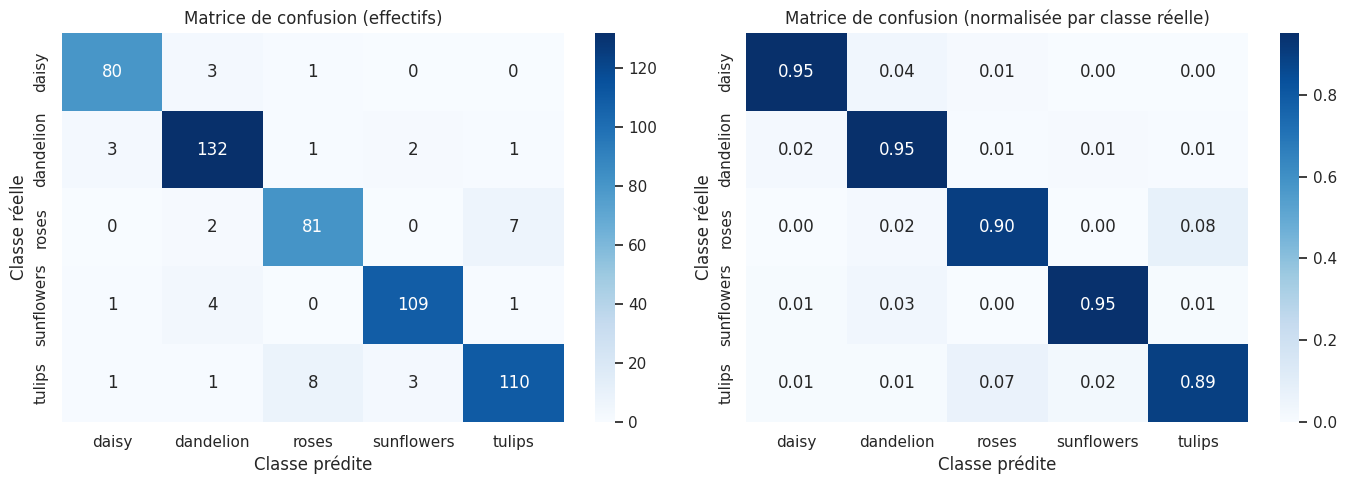

In [59]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)    # normalisation par ligne (rappel par classe)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title("Matrice de confusion (effectifs)")

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title("Matrice de confusion (normalisée par classe réelle)")

for ax in axes:
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")
plt.tight_layout()
plt.show()

Nombre d'erreurs : 39 sur 551 images de test


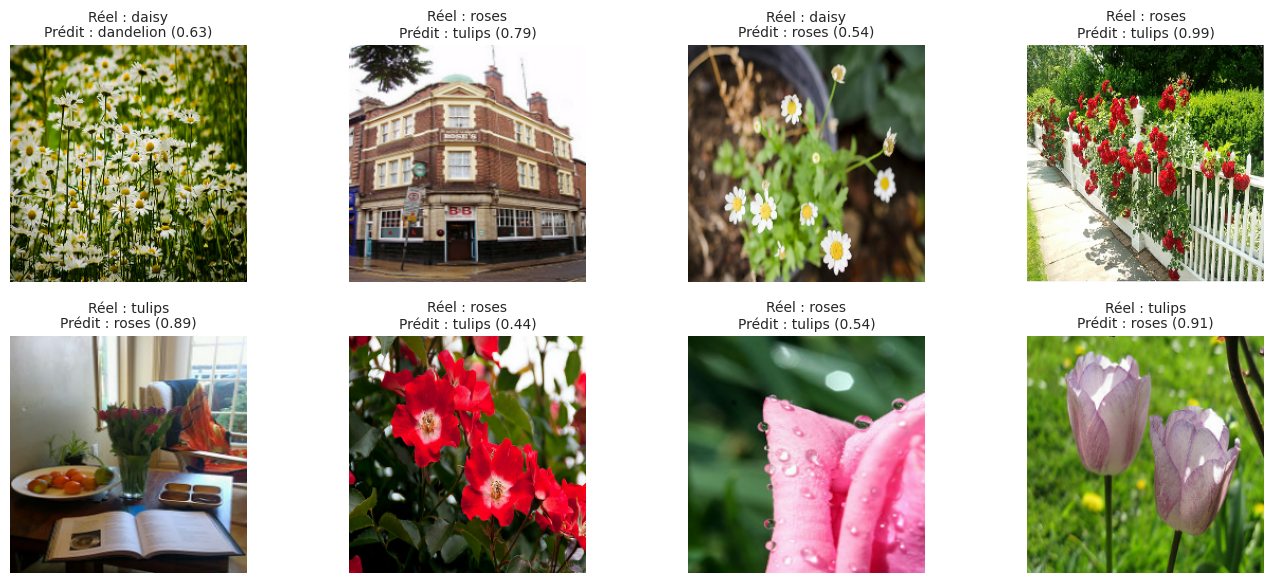

In [60]:
# --- Analyse des erreurs : quelques images mal classées ---
x_test_all = np.concatenate([x.numpy() for x, _ in test_ds]).astype("uint8")
errors = np.where(y_pred != y_true)[0]
print(f"Nombre d'erreurs : {len(errors)} sur {len(y_true)} images de test")

n_show = min(8, len(errors))
if n_show > 0:
    plt.figure(figsize=(14, 6))
    for i, idx in enumerate(errors[:n_show]):
        plt.subplot(2, 4, i + 1)
        plt.imshow(x_test_all[idx])
        plt.title(f"Réel : {class_names[y_true[idx]]}\nPrédit : {class_names[y_pred[idx]]} "
                  f"({y_proba[idx].max():.2f})", fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

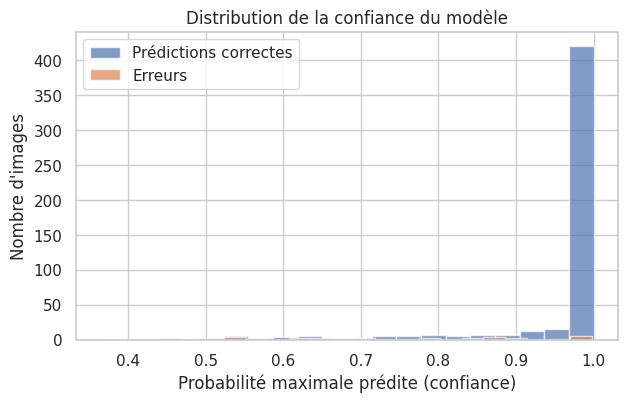

In [61]:
# --- Confiance du modèle : prédictions correctes vs erreurs ---
confidence = y_proba.max(axis=1)
correct = (y_pred == y_true)

plt.figure(figsize=(7, 4))
plt.hist(confidence[correct], bins=20, alpha=0.7, label="Prédictions correctes")
if (~correct).any():
    plt.hist(confidence[~correct], bins=20, alpha=0.7, label="Erreurs")
plt.xlabel("Probabilité maximale prédite (confiance)")
plt.ylabel("Nombre d'images")
plt.title("Distribution de la confiance du modèle")
plt.legend()
plt.show()

**Analyse (à adapter à vos résultats).**
* Le `classification_report` permet d'identifier les classes les plus faciles et les plus difficiles. Les confusions les plus fréquentes concernent en général des fleurs aux formes ou couleurs proches (par exemple roses et tulipes).
* Les erreurs ont en général une confiance plus faible que les prédictions correctes : la probabilité softmax est un indicateur utile (mais imparfait) de l'incertitude du modèle.
* Certaines erreurs viennent de la qualité des images (plusieurs fleurs, fond chargé, fleur non visible) plutôt que du modèle.

---
## 11. Comparaison, sauvegarde, inférence et conclusion

### 11.1 Comparaison des approches (jeu de test)

,Test loss,Test accuracy (%),Paramètres entraînables,Paramètres figés
CNN from scratch,0.8242,69.87,12939077.0,0.0
ResNet50V2 : base gelée,0.3081,88.02,10245.0,23564800.0
ResNet50V2 : fine-tuning,0.2252,92.92,14436357.0,9138688.0
ResNet50V2 : fine-tuning optimisé,0.2838,88.93,3420165.0,20154880.0


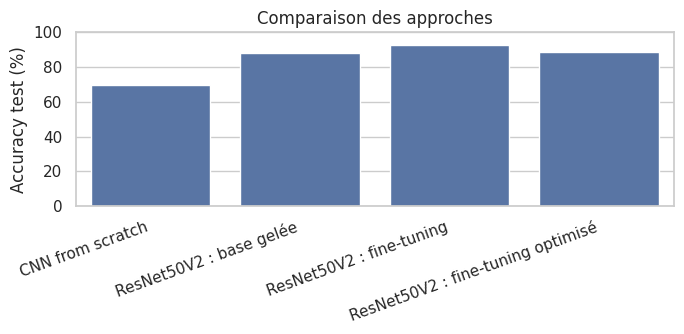

In [62]:
df_results = pd.DataFrame(results).T
df_results["Test accuracy (%)"] = (df_results["Test accuracy"] * 100).round(2)
df_results["Test loss"] = df_results["Test loss"].round(4)
display(df_results[["Test loss", "Test accuracy (%)", "Paramètres entraînables", "Paramètres figés"]])

plt.figure(figsize=(7, 3.5))
sns.barplot(x=df_results.index, y=df_results["Test accuracy"] * 100)
plt.ylabel("Accuracy test (%)")
plt.xlabel("")
plt.title("Comparaison des approches")
plt.xticks(rotation=20, ha='right')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### 11.2 Sauvegarde du modèle et inférence sur une nouvelle image

Modèle sauvegardé : flowers_resnet50v2_finetuned.keras
117948/117948 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


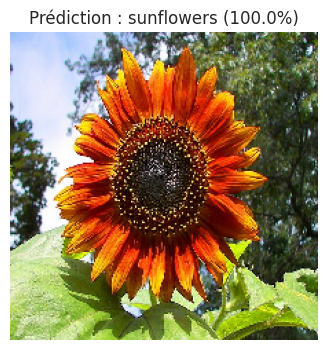

  sunflowers   100.0%
  dandelion    0.0%
  daisy        0.0%


In [63]:
model.save("flowers_resnet50v2_finetuned.keras")
print("Modèle sauvegardé : flowers_resnet50v2_finetuned.keras")

def predict_image(path, top_k=3):
    """Prédit la classe d'une image (fichier local) et affiche les k meilleures probabilités."""
    img = keras.utils.load_img(path, target_size=IMG_SIZE)
    arr = keras.utils.img_to_array(img)
    proba = model.predict(arr[None, ...], verbose=0)[0]
    best = np.argsort(proba)[::-1][:top_k]

    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Prédiction : {class_names[best[0]]} ({proba[best[0]]:.1%})")
    plt.show()
    for i in best:
        print(f"  {class_names[i]:<12} {proba[i]:.1%}")

# Exemple avec une image externe (nécessite un accès Internet)
try:
    sunflower_path = keras.utils.get_file(
        "sunflower_test.jpg",
        "https://storage.googleapis.com/download.tensorflow.org/example_images/592px-Red_sunflower.jpg",
    )
    predict_image(sunflower_path)
except Exception as e:
    print("Image externe non disponible :", e)

### 11.3 Conclusion

**Synthèse de la démarche.**
Nous avons comparé quatre modèles sur la classification de 5 types de fleurs : un petit CNN entraîné **from scratch**, un **ResNet50V2 pré-entraîné avec base gelée**, le même modèle après **fine-tuning** avec une configuration raisonnée, puis après fine-tuning avec une configuration **optimisée** par Grid Search et Random Search. Le tableau de la section 11.1 résume les résultats sur le jeu de test.

**Ce que l'on retient (à confirmer avec vos chiffres).**
1. Le **transfert d'apprentissage** apporte un gain important par rapport à un CNN entraîné depuis zéro, car les caractéristiques apprises sur ImageNet sont réutilisables et le jeu de données est petit.
2. Le **fine-tuning** apporte une amélioration supplémentaire, plus modeste, à condition d'utiliser un **learning rate très faible** et de laisser les couches BatchNorm figées.
3. L'**optimisation des hyperparamètres** (Grid Search, Random Search, SciKeras avec validation croisée) permet de **vérifier** les choix initiaux de manière systématique. Le Grid Search offre une vue complète mais coûteuse ; le Random Search, avec un tirage logarithmique du learning rate, explore plus de valeurs avec moins d'essais. Le gain obtenu doit être comparé à la variabilité entre exécutions avant d'être interprété.
4. La **régularisation** (L2, Dropout, data augmentation), l'**early stopping** et le **learning rate adaptatif** limitent le sur-apprentissage et stabilisent l'entraînement.
5. La sélection des hyperparamètres s'est faite sur la **validation** ; le **test** est resté réservé à l'évaluation finale, ce qui évite une estimation trop optimiste.
6. L'**évaluation** ne se limite pas à l'accuracy : rapport par classe, matrice de confusion et analyse des erreurs expliquent où le modèle se trompe.

**Limites.**
* Un seul découpage train / validation / test et des essais courts (quelques époques) : le classement des configurations peut varier d'une graine à l'autre.
* Espace de recherche restreint (3 hyperparamètres) et peu d'essais.
* Jeu de données de taille modeste, avec quelques images ambiguës.

**Perspectives.**
* Augmenter le budget de recherche, ou utiliser une optimisation bayésienne (Keras Tuner, Optuna) à la place d'un tirage aléatoire.
* Inclure d'autres hyperparamètres : $\lambda$ de la L2, taille de batch, type d'optimiseur, intensité de la data augmentation.
* Tester d'autres architectures pré-entraînées (EfficientNet, MobileNetV2, DenseNet) ou des **Transformers de vision** (mécanismes d'attention).
* Utiliser des learning rates différents selon la profondeur des couches (*discriminative learning rates*).
* Ajouter des méthodes d'explicabilité comme **Grad-CAM**.